# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


Cada fila representa una flor Iris. Instancias: 150; características: 4.
Dimensiones X: (150, 4) | dimensiones y: (150,)
Características (longitudes en cm): sepal length (cm), sepal width (cm), petal length (cm), petal width (cm)
Clases: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),clase
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


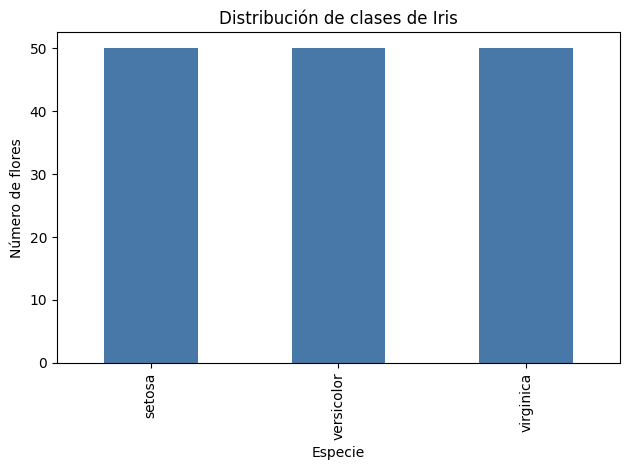

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.neighbors import KNeighborsRegressor

RANDOM_STATE = 42
iris = load_iris()
X_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
y_iris = pd.Series(iris.target, name='clase')
class_names = iris.target_names

print(f'Cada fila representa una flor Iris. Instancias: {len(X_iris)}; características: {X_iris.shape[1]}.')
print('Dimensiones X:', X_iris.shape, '| dimensiones y:', y_iris.shape)
print('Características (longitudes en cm):', ', '.join(iris.feature_names))
print('Clases:', dict(zip(class_names, np.bincount(y_iris))))
display(X_iris.head().assign(clase=y_iris.map(dict(enumerate(class_names)))))

ax = y_iris.map(dict(enumerate(class_names))).value_counts().reindex(class_names).plot.bar(color='#4778a8')
ax.set(title='Distribución de clases de Iris', xlabel='Especie', ylabel='Número de flores')
plt.tight_layout()
plt.show()


# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

### Predicción inicial

1. Regresión logística, SVM y MLP deberían ser más sensibles a la escala: usan distancias, productos internos o optimización con gradientes. Estandarizar también hace comparables las contribuciones de las variables. Los árboles dividen por umbrales y suelen ser poco sensibles a cambios de unidades.
2. Un árbol poco profundo o un modelo lineal tendería a producir una frontera más simple; la complejidad del árbol depende de su profundidad.
3. El resultado depende de la muestra, la partición, los hiperparámetros y la forma real de las fronteras. La validación sirve para elegir ajustes; la prueba se reserva para la comparación final.


,Modelo,Accuracy validación,F1 macro validación
2,SVM lineal,0.967,0.967
3,Árbol,0.967,0.967
5,Gradient Boosting,0.967,0.967
0,Gaussian NB,0.933,0.933
1,Regresión logística,0.933,0.933
4,Random Forest,0.933,0.933
6,MLP,0.400,0.297


Regresión logística: ajuste elegido por validación; F1 macro=0.933, accuracy=0.933
SVM lineal: ajuste elegido por validación; F1 macro=0.967, accuracy=0.967
Árbol: ajuste elegido por validación; F1 macro=0.967, accuracy=0.967


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
2,SVM lineal,StandardScaler (dentro del pipeline),kernel=linear; C elegido en validación,0.967,0.967
5,Gradient Boosting,StandardScaler (dentro del pipeline),100 etapas; learning_rate=0.05; max_depth=2,0.967,0.967
0,Gaussian NB,StandardScaler (dentro del pipeline),var_smoothing=1e-9,0.933,0.933
1,Regresión logística,StandardScaler (dentro del pipeline),C elegido en validación,0.933,0.933
4,Random Forest,StandardScaler (dentro del pipeline),200 árboles; sin profundidad máxima,0.900,0.898
3,Árbol,StandardScaler (dentro del pipeline),max_depth elegido en validación,0.867,0.865
6,MLP,StandardScaler (dentro del pipeline),32 neuronas; alpha=0.001; early stopping,0.333,0.185


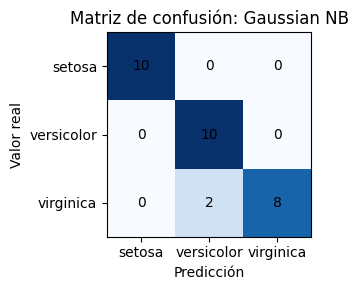

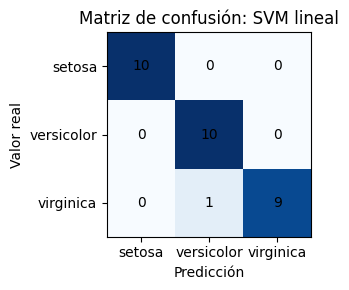

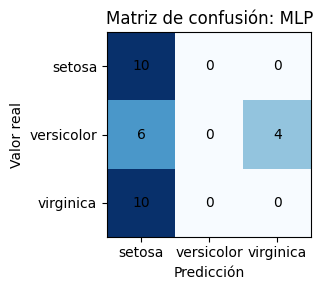

Dos errores inspeccionados del modelo Gaussian NB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),real,predicción
134,6.1,2.6,5.6,1.4,virginica,versicolor
133,6.3,2.8,5.1,1.5,virginica,versicolor


In [2]:
# Particiones estratificadas comunes para todos los clasificadores.
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X_iris, y_iris, test_size=0.40, random_state=RANDOM_STATE, stratify=y_iris)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_tmp)

# Todas las características se estandarizan dentro del pipeline; el scaler
# aprende sus parámetros solo en entrenamiento. Para árboles es innecesario,
# pero se mantiene el mismo protocolo solicitado.
def make_classifiers():
    return {
        'Gaussian NB': make_pipeline(StandardScaler(), GaussianNB()),
        'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE)),
        'SVM lineal': make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0)),
        'Árbol': make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
        'Random Forest': make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=None, random_state=RANDOM_STATE)),
        'Gradient Boosting': make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE)),
        'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32,), alpha=0.001, max_iter=3000, early_stopping=True, random_state=RANDOM_STATE))
    }

models = make_classifiers()
valid_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    valid_rows.append({'Modelo':name, 'Accuracy validación':accuracy_score(y_valid,pred),
                       'F1 macro validación':f1_score(y_valid,pred,average='macro')})
valid_results = pd.DataFrame(valid_rows).sort_values(['F1 macro validación','Accuracy validación'], ascending=False)
display(valid_results.round(3))

# Ajustes limitados con validación: se prueban alternativas pequeñas para
# logística, SVM y árbol. Se elige por F1 macro y luego accuracy.
candidate_specs = {
    'Regresión logística': [LogisticRegression(C=c,max_iter=2000,random_state=RANDOM_STATE) for c in (0.1,1,10)],
    'SVM lineal': [SVC(kernel='linear',C=c) for c in (0.1,1,10)],
    'Árbol': [DecisionTreeClassifier(max_depth=d,random_state=RANDOM_STATE) for d in (2,3,5)]
}
for name, candidates in candidate_specs.items():
    scored=[]
    for est in candidates:
        pipe=make_pipeline(StandardScaler(),est)
        pipe.fit(X_train,y_train)
        pv=pipe.predict(X_valid)
        scored.append((f1_score(y_valid,pv,average='macro'),accuracy_score(y_valid,pv),pipe,est))
    best=max(scored,key=lambda row:(row[0],row[1]))
    models[name]=best[2]
    print(f'{name}: ajuste elegido por validación; F1 macro={best[0]:.3f}, accuracy={best[1]:.3f}')

# Configuraciones congeladas. Ajustamos los pipelines sobre train + validación
# y usamos test una sola vez para la evaluación final.
X_fit=pd.concat([X_train,X_valid]); y_fit=pd.concat([y_train,y_valid])
test_rows=[]; test_predictions={}
params={
 'Gaussian NB':'var_smoothing=1e-9', 'Regresión logística':'C elegido en validación',
 'SVM lineal':'kernel=linear; C elegido en validación', 'Árbol':'max_depth elegido en validación',
 'Random Forest':'200 árboles; sin profundidad máxima',
 'Gradient Boosting':'100 etapas; learning_rate=0.05; max_depth=2',
 'MLP':'32 neuronas; alpha=0.001; early stopping'}
for name,model in models.items():
    model.fit(X_fit,y_fit)
    pred=model.predict(X_test); test_predictions[name]=pred
    test_rows.append({'Modelo':name,'Transformación':'StandardScaler (dentro del pipeline)',
                      'Hiperparámetros principales':params[name],
                      'Accuracy de prueba':accuracy_score(y_test,pred),
                      'F1 macro de prueba':f1_score(y_test,pred,average='macro')})
test_results=pd.DataFrame(test_rows).sort_values(['F1 macro de prueba','Accuracy de prueba'],ascending=False)
display(test_results.round(3))

for name in ('Gaussian NB','SVM lineal','MLP'):
    cm=confusion_matrix(y_test,test_predictions[name],labels=np.arange(len(class_names)))
    fig,ax=plt.subplots(figsize=(4,3))
    ax.imshow(cm,cmap='Blues')
    ax.set(xticks=range(3),xticklabels=class_names,yticks=range(3),yticklabels=class_names,
           xlabel='Predicción',ylabel='Valor real',title=f'Matriz de confusión: {name}')
    for (i,j),v in np.ndenumerate(cm): ax.text(j,i,str(v),ha='center',va='center')
    plt.tight_layout(); plt.show()

# Dos errores del primer modelo con equivocaciones, para inspección concreta.
error_model=next((n for n in ('Gaussian NB','SVM lineal','MLP') if np.any(test_predictions[n]!=y_test.to_numpy())),None)
if error_model:
    err=np.flatnonzero(test_predictions[error_model]!=y_test.to_numpy())[:2]
    error_examples=X_test.iloc[err].copy()
    error_examples['real']=y_test.iloc[err].map(dict(enumerate(class_names))).to_numpy()
    error_examples['predicción']=pd.Series(test_predictions[error_model][err],index=error_examples.index).map(dict(enumerate(class_names)))
    print('Dos errores inspeccionados del modelo',error_model)
    display(error_examples)
else:
    print('Los modelos inspeccionados no cometieron errores en esta partición de prueba.')


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

### Interpretación de los resultados

La primera fila de la tabla de prueba identifica el mejor resultado observado en esta partición. Accuracy es la proporción total de aciertos; F1 macro promedia el F1 de cada clase con el mismo peso. En Iris las clases están equilibradas, así que normalmente cuentan una historia parecida; en datos desequilibrados pueden diferir.

La métrica macro calcula la métrica por clase y luego promedia sin ponderar; la micro suma los aciertos y errores globales antes de calcularla, por lo que da más peso a las clases con más ejemplos. En clasificación multiclase de etiqueta única, F1 micro coincide con accuracy.

Gaussian Naive Bayes suele ser el más sencillo de programar: ajuste y predicción requieren pocas decisiones. El MLP puede representar fronteras no lineales mediante capas ocultas, frente a la frontera lineal de logística y SVM lineal; esa flexibilidad no garantiza una mejora en un conjunto pequeño.

Las filas de errores permiten ver qué valores de sépalo y pétalo acompañaron una confusión concreta. Dos observaciones pueden parecerse en sus características y ser difíciles de separar. Esto describe el caso, pero no demuestra la causa del error ni una causa biológica: también influyen el tamaño de muestra, el solapamiento de clases y la variabilidad aleatoria.


In [3]:
diabetes=load_diabetes()
X=pd.DataFrame(diabetes.data,columns=diabetes.feature_names)
y=pd.Series(diabetes.target,name='progresión de la enfermedad')
print(diabetes.DESCR[:2200])
print('Dimensiones:',X.shape,'| objetivo:',y.shape)
print('Variables:',', '.join(X.columns))
print('Objetivo: medida cuantitativa de progresión de diabetes un año después del inicio del estudio.')
print('La descripción indica que las características fueron centradas en la media y escaladas por la desviación estándar multiplicada por la raíz de n muestras. Por eso sus magnitudes no deben leerse como unidades clínicas originales.')

# Particiones comunes: 60% entrenamiento, 20% validación y 20% prueba.
X_train,X_tmp,y_train,y_tmp=train_test_split(X,y,test_size=0.40,random_state=RANDOM_STATE)
X_valid,X_test,y_valid,y_test=train_test_split(X_tmp,y_tmp,test_size=0.50,random_state=RANDOM_STATE)


.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

## Predicción inicial e interpretación conceptual

Un modelo más flexible no necesariamente tendrá menor error en datos nuevos. Puede reducir el error de entrenamiento y, a la vez, ajustarse al ruido; la validación ayuda a equilibrar sesgo y varianza.

### Comparación de regresores

Se comparan ocho métodos sobre particiones compartidas. Los escaladores se ajustan dentro de cada pipeline usando solo entrenamiento. La transformación estándar del objetivo para el MLP también se aprende exclusivamente en entrenamiento; la evaluación vuelve a la escala original.


,Modelo,MAE validación,RMSE validación,R² validación
0,Regresión lineal,38.22,49.15,0.58
1,Ridge,38.29,49.20,0.58
2,Lasso,38.30,49.20,0.58
6,Gradient Boosting,40.03,50.90,0.55
5,Random Forest,41.94,52.89,0.51
3,kNN,45.17,56.63,0.44
4,Árbol,46.98,58.09,0.41
7,MLP,54.45,66.62,0.23


Ridge: ajuste elegido con validación: 0.01, RMSE=49.15
Lasso: ajuste elegido con validación: 0.001, RMSE=49.15
kNN: ajuste elegido con validación: 11, RMSE=54.51


,Modelo,MAE,RMSE,R²
5,Random Forest,44.06,55.23,0.47
6,Gradient Boosting,45.55,55.86,0.46
0,Regresión lineal,46.68,56.65,0.45
1,Ridge,46.68,56.65,0.45
2,Lasso,46.68,56.65,0.45
3,kNN,45.70,56.81,0.44
4,Árbol,48.51,61.81,0.34
7,MLP,51.41,65.81,0.25


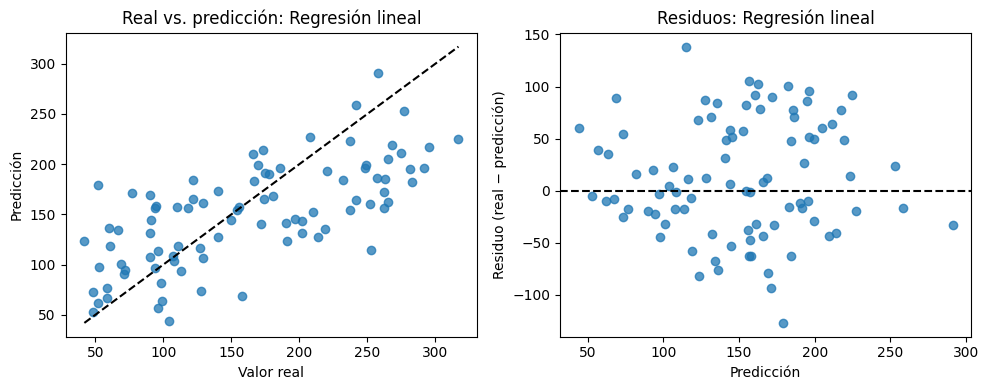

Dos errores absolutos mayores: Regresión lineal


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,real,predicción,error absoluto
304,0.041708,0.050680,-0.038540,0.052858,0.076860,0.116430,-0.039719,0.071210,-0.022517,-0.013504,253.0,114.69477,138.30523
380,0.016281,-0.044642,0.026128,0.058608,-0.060735,-0.044215,-0.013948,-0.033958,-0.051404,-0.025930,52.0,179.14039,127.14039


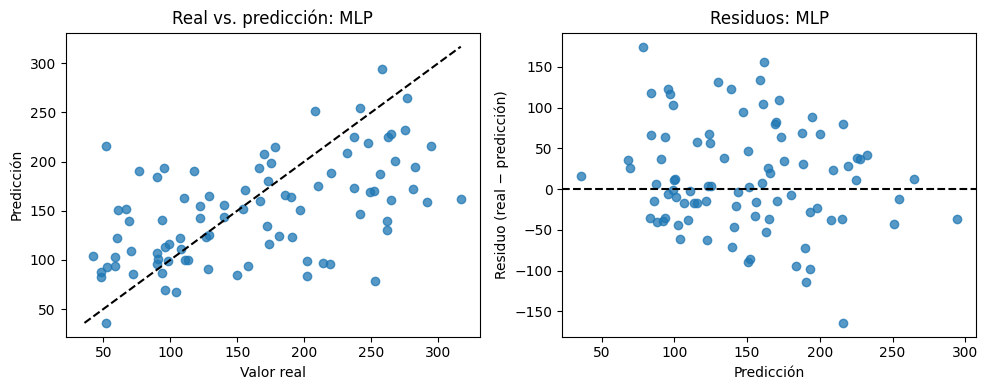

Dos errores absolutos mayores: MLP


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,real,predicción,error absoluto
304,0.041708,0.050680,-0.038540,0.052858,0.076860,0.116430,-0.039719,0.071210,-0.022517,-0.013504,253.0,78.228219,174.771781
380,0.016281,-0.044642,0.026128,0.058608,-0.060735,-0.044215,-0.013948,-0.033958,-0.051404,-0.025930,52.0,216.049696,164.049696


In [4]:
# El objetivo del MLP se estandariza con parámetros de entrenamiento solamente.
y_mean=float(y_train.mean()); y_scale=float(y_train.std())
def y_transform(values): return (np.asarray(values)-y_mean)/y_scale
def y_inverse(values): return np.asarray(values)*y_scale+y_mean

def regressors():
    return {
      'Regresión lineal':make_pipeline(StandardScaler(),LinearRegression()),
      'Ridge':make_pipeline(StandardScaler(),Ridge(alpha=1.0)),
      'Lasso':make_pipeline(StandardScaler(),Lasso(alpha=0.1,max_iter=20000)),
      'kNN':make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=7)),
      'Árbol':DecisionTreeRegressor(max_depth=3,random_state=RANDOM_STATE),
      'Random Forest':RandomForestRegressor(n_estimators=250,min_samples_leaf=3,random_state=RANDOM_STATE),
      'Gradient Boosting':GradientBoostingRegressor(n_estimators=100,learning_rate=0.05,max_depth=2,random_state=RANDOM_STATE),
      'MLP':make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(32,),alpha=0.01,learning_rate_init=0.01,max_iter=3000,early_stopping=True,random_state=RANDOM_STATE))
    }

models=regressors()
def fit_model(name,model,Xtr,ytr):
    if name=='MLP': model.fit(Xtr,y_transform(ytr))
    else: model.fit(Xtr,ytr)
def predict_model(name,model,Xv):
    pred=model.predict(Xv)
    return y_inverse(pred) if name=='MLP' else pred

valid_rows=[]
for name,model in models.items():
    fit_model(name,model,X_train,y_train)
    pred=predict_model(name,model,X_valid)
    valid_rows.append({'Modelo':name,'MAE validación':mean_absolute_error(y_valid,pred),
                       'RMSE validación':mean_squared_error(y_valid,pred)**0.5,
                       'R² validación':r2_score(y_valid,pred)})
display(pd.DataFrame(valid_rows).sort_values('RMSE validación').round(2))

# Ajustes acotados para Ridge, Lasso y kNN con validación.
for name, candidates in {
 'Ridge':[0.01,0.1,1,10,100], 'Lasso':[0.001,0.01,0.1,1,10], 'kNN':[3,5,7,11,15]
}.items():
    scored=[]
    for value in candidates:
        if name=='Ridge': est=make_pipeline(StandardScaler(),Ridge(alpha=value))
        elif name=='Lasso': est=make_pipeline(StandardScaler(),Lasso(alpha=value,max_iter=20000))
        else: est=make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=value))
        fit_model(name,est,X_train,y_train)
        pv=predict_model(name,est,X_valid)
        scored.append((mean_squared_error(y_valid,pv)**0.5,value,est))
    best=min(scored,key=lambda z:z[0]); models[name]=best[2]
    print(f'{name}: ajuste elegido con validación: {best[1]}, RMSE={best[0]:.2f}')

# Congelar y medir una sola vez en prueba. Para el reporte final se entrena
# con train+validación; la escala del objetivo del MLP se recalcula solo allí.
X_fit=pd.concat([X_train,X_valid]); y_fit=pd.concat([y_train,y_valid])
y_mean=float(y_fit.mean()); y_scale=float(y_fit.std())
test_rows=[]; predictions={}
for name,model in models.items():
    fit_model(name,model,X_fit,y_fit)
    pred=predict_model(name,model,X_test); predictions[name]=pred
    test_rows.append({'Modelo':name,'MAE':mean_absolute_error(y_test,pred),
                      'RMSE':mean_squared_error(y_test,pred)**0.5,'R²':r2_score(y_test,pred)})
results=pd.DataFrame(test_rows).sort_values('RMSE')
display(results.round(2))

for name in ('Regresión lineal','MLP'):
    pred=predictions[name]; residual=y_test.to_numpy()-pred
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    axes[0].scatter(y_test,pred,alpha=.75); lo=min(y_test.min(),pred.min()); hi=max(y_test.max(),pred.max())
    axes[0].plot([lo,hi],[lo,hi],'--',color='black'); axes[0].set(xlabel='Valor real',ylabel='Predicción',title=f'Real vs. predicción: {name}')
    axes[1].scatter(pred,residual,alpha=.75); axes[1].axhline(0,color='black',linestyle='--')
    axes[1].set(xlabel='Predicción',ylabel='Residuo (real − predicción)',title=f'Residuos: {name}')
    plt.tight_layout(); plt.show()
    hardest=np.argsort(np.abs(residual))[-2:][::-1]
    examples=X_test.iloc[hardest].copy(); examples['real']=y_test.iloc[hardest].to_numpy()
    examples['predicción']=pred[hardest]; examples['error absoluto']=np.abs(residual[hardest])
    print(f'Dos errores absolutos mayores: {name}'); display(examples)


### Regularización e interpretación

La siguiente comparación ajusta Ridge y Lasso con varios valores de alpha. El escalamiento se realiza dentro de cada pipeline y todas las decisiones se toman con entrenamiento y validación. Se informa también el error de entrenamiento para observar posibles brechas de ajuste.


,Modelo,alpha,RMSE entrenamiento,RMSE validación,Coeficientes nulos,Norma L2 coeficientes
0,Ridge,0.001,54.285,49.150,0,57.947
1,Ridge,0.010,54.285,49.150,0,57.847
2,Ridge,0.100,54.285,49.156,0,56.892
3,Ridge,1.000,54.297,49.203,0,50.572
4,Ridge,10.000,54.395,49.373,0,41.090
5,Ridge,100.000,55.440,50.815,0,31.935
6,Lasso,0.001,54.285,49.150,0,57.816
7,Lasso,0.010,54.285,49.157,0,56.556
8,Lasso,0.100,54.302,49.204,0,49.263
9,Lasso,1.000,54.473,49.525,2,41.095


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
Ridge alpha=0.001,0.851,-10.787,28.354,17.359,-31.563,16.915,0.691,6.820,28.354,1.487
Ridge alpha=0.01,0.853,-10.786,28.355,17.358,-31.461,16.835,0.647,6.808,28.314,1.488
Ridge alpha=0.1,0.870,-10.774,28.369,17.345,-30.482,16.070,0.223,6.690,27.926,1.496
Ridge alpha=1,0.992,-10.678,28.440,17.239,-23.436,10.562,-2.811,5.871,25.118,1.569
Ridge alpha=10,1.308,-10.120,27.852,16.671,-8.578,-0.948,-8.787,4.683,18.778,2.095
Ridge alpha=100,1.840,-6.659,21.480,13.338,-2.305,-3.167,-9.163,5.418,13.592,4.408
Lasso alpha=0.001,0.853,-10.784,28.356,17.357,-31.428,16.814,0.627,6.794,28.305,1.487
Lasso alpha=0.01,0.865,-10.758,28.380,17.338,-30.113,15.827,0.004,6.545,27.817,1.484
Lasso alpha=0.1,0.903,-10.517,28.590,17.185,-21.672,9.199,-3.454,5.538,24.569,1.469
Lasso alpha=1,0.112,-8.545,28.764,16.263,-5.822,-0.000,-10.836,0.000,19.278,0.970


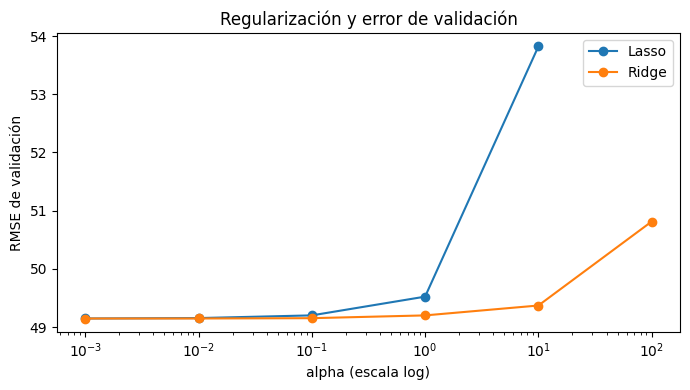

In [5]:
# Rejilla de regularización y reporte de coeficientes en la escala estandarizada.
reg_rows=[]; coefficient_rows=[]
for kind,alphas in [('Ridge',[0.001,0.01,0.1,1,10,100]),('Lasso',[0.001,0.01,0.1,1,10])]:
    for alpha in alphas:
        estimator=Ridge(alpha=alpha) if kind=='Ridge' else Lasso(alpha=alpha,max_iter=20000)
        pipe=make_pipeline(StandardScaler(),estimator).fit(X_train,y_train)
        train_pred=pipe.predict(X_train); valid_pred=pipe.predict(X_valid)
        coef=pipe[-1].coef_
        reg_rows.append({'Modelo':kind,'alpha':alpha,'RMSE entrenamiento':mean_squared_error(y_train,train_pred)**0.5,
                         'RMSE validación':mean_squared_error(y_valid,valid_pred)**0.5,
                         'Coeficientes nulos':int(np.isclose(coef,0).sum()),
                         'Norma L2 coeficientes':float(np.linalg.norm(coef))})
        coefficient_rows.append(pd.Series(coef,index=X.columns,name=f'{kind} alpha={alpha}'))
reg_results=pd.DataFrame(reg_rows)
display(reg_results.round(3))
coef_table=pd.DataFrame(coefficient_rows,index=[f'{r["Modelo"]} alpha={r["alpha"]}' for r in reg_rows])
display(coef_table.round(3))

fig,ax=plt.subplots(figsize=(7,4))
for kind,group in reg_results.groupby('Modelo'):
    ax.plot(group['alpha'],group['RMSE validación'],marker='o',label=kind)
ax.set_xscale('log'); ax.set(xlabel='alpha (escala log)',ylabel='RMSE de validación',title='Regularización y error de validación')
ax.legend(); plt.tight_layout(); plt.show()


### Respuestas

1. ¿Qué modelo tuvo el mejor desempeño?
El modelo con mejor desempeño es el que encabeza la tabla de prueba según RMSE; el ranking puede cambiar si se prioriza MAE. Estas métricas se reportan en las unidades del objetivo.
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
MAE penaliza cada error en proporción a su tamaño; RMSE eleva al cuadrado los errores antes de promediar, por lo que penaliza más los errores grandes.
3. ¿Cómo se interpreta un R² negativo?
Un R² negativo significa que, en esa muestra de prueba, las predicciones son peores que predecir siempre la media del objetivo de prueba.
4. ¿Qué efecto tuvo aumentar la regularización?
Al aumentar alpha, Ridge reduce gradualmente la magnitud de coeficientes; Lasso puede llevar algunos coeficientes exactamente a cero. Demasiada regularización puede causar subajuste. La tabla y la curva muestran el efecto concreto en este split.
5. ¿Qué puede explicar los errores grandes?
Los ejemplos con mayores errores permiten buscar valores atípicos o casos difíciles, pero no atribuyen causalidad. Puede haber ruido, variables omitidas, heterogeneidad clínica o límites del modelo.
6. ¿Un coeficiente predictivo demuestra una relación causal?
No. Un coeficiente predictivo describe una asociación condicionada al modelo y a las variables incluidas. Para una conclusión causal hacen falta supuestos y un diseño de identificación causal.
